In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("stock_market_analysis_dataset.csv")

In [3]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])


In [4]:
# Display first 5 records
print("First 5 records:")
print(df.head())


First 5 records:
        Date     Open     High      Low    Close   Volume  Daily_Return_%  \
0 2025-01-02  1002.65  1017.17   999.31  1006.38  4921590             NaN   
1 2025-01-03  1004.88  1010.90   988.50  1005.11  3034937          -0.126   
2 2025-01-06  1000.22  1027.63   984.36  1013.36  3657473           0.821   
3 2025-01-07  1028.24  1036.78  1016.76  1032.47  1312461           1.886   
4 2025-01-08  1028.94  1036.68  1017.41  1029.98  4927036          -0.241   

   MA_20  MA_50  
0    NaN    NaN  
1    NaN    NaN  
2    NaN    NaN  
3    NaN    NaN  
4    NaN    NaN  


In [5]:
# Dataset information
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            260 non-null    datetime64[ns]
 1   Open            260 non-null    float64       
 2   High            260 non-null    float64       
 3   Low             260 non-null    float64       
 4   Close           260 non-null    float64       
 5   Volume          260 non-null    int64         
 6   Daily_Return_%  259 non-null    float64       
 7   MA_20           241 non-null    float64       
 8   MA_50           211 non-null    float64       
dtypes: datetime64[ns](1), float64(7), int64(1)
memory usage: 18.4 KB
None


In [6]:
# Statistical summary
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
                      Date         Open         High          Low  \
count                  260   260.000000   260.000000   260.000000   
mean   2025-07-02 16:48:00   978.695038   989.196500   967.480077   
min    2025-01-02 00:00:00   887.240000   892.290000   869.150000   
25%    2025-04-02 18:00:00   922.150000   931.607500   911.402500   
50%    2025-07-02 12:00:00   952.920000   963.375000   939.220000   
75%    2025-10-01 06:00:00  1024.370000  1035.420000  1013.770000   
max    2025-12-31 00:00:00  1139.690000  1148.910000  1128.870000   
std                    NaN    69.907778    70.428787    69.525610   

             Close        Volume  Daily_Return_%        MA_20        MA_50  
count   260.000000  2.600000e+02      259.000000   241.000000   211.000000  
mean    978.729731  2.820069e+06        0.053726   971.490456   962.267962  
min     884.320000  5.224310e+05       -3.056000   900.190000   915.410000  
25%     921.800000  1.754244e+06       -0.786500

In [7]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Date               0
Open               0
High               0
Low                0
Close              0
Volume             0
Daily_Return_%     1
MA_20             19
MA_50             49
dtype: int64


In [8]:
# --------------------------------------------------
# 1. Closing Price Analysis
# --------------------------------------------------

print("\nHighest Closing Price:")
print(df["Close"].max())

print("\nLowest Closing Price:")
print(df["Close"].min())



Highest Closing Price:
1136.63

Lowest Closing Price:
884.32


In [9]:
# --------------------------------------------------
# 2. Daily Return Analysis
# --------------------------------------------------

print("\nAverage Daily Return:")
print(df["Daily_Return_%"].mean())

print("\nMaximum Daily Return:")
print(df["Daily_Return_%"].max())

print("\nMinimum Daily Return:")
print(df["Daily_Return_%"].min())



Average Daily Return:
0.053725868725868715

Maximum Daily Return:
4.774

Minimum Daily Return:
-3.056


In [10]:
# --------------------------------------------------
# 3. Highest Trading Volume
# --------------------------------------------------

highest_volume = df.loc[df["Volume"].idxmax()]

print("\nDay with Highest Trading Volume:")
print(highest_volume)



Day with Highest Trading Volume:
Date              2025-07-28 00:00:00
Open                           905.39
High                           909.53
Low                             896.6
Close                          905.91
Volume                        4995511
Daily_Return_%                 -1.533
MA_20                          926.92
MA_50                          923.32
Name: 147, dtype: object


In [11]:
# --------------------------------------------------
# 4. Moving Average Analysis
# --------------------------------------------------

df["MA_20"] = df["Close"].rolling(window=20).mean()
df["MA_50"] = df["Close"].rolling(window=50).mean()

print("\nLatest Moving Averages:")
print(df[["Date", "Close", "MA_20", "MA_50"]].tail())


Latest Moving Averages:
          Date    Close      MA_20      MA_50
255 2025-12-25  1110.52  1093.4015  1088.7548
256 2025-12-26  1127.98  1095.4540  1091.3142
257 2025-12-29  1118.89  1096.9085  1093.5600
258 2025-12-30  1125.32  1099.0940  1095.8016
259 2025-12-31  1136.28  1101.2495  1097.2950


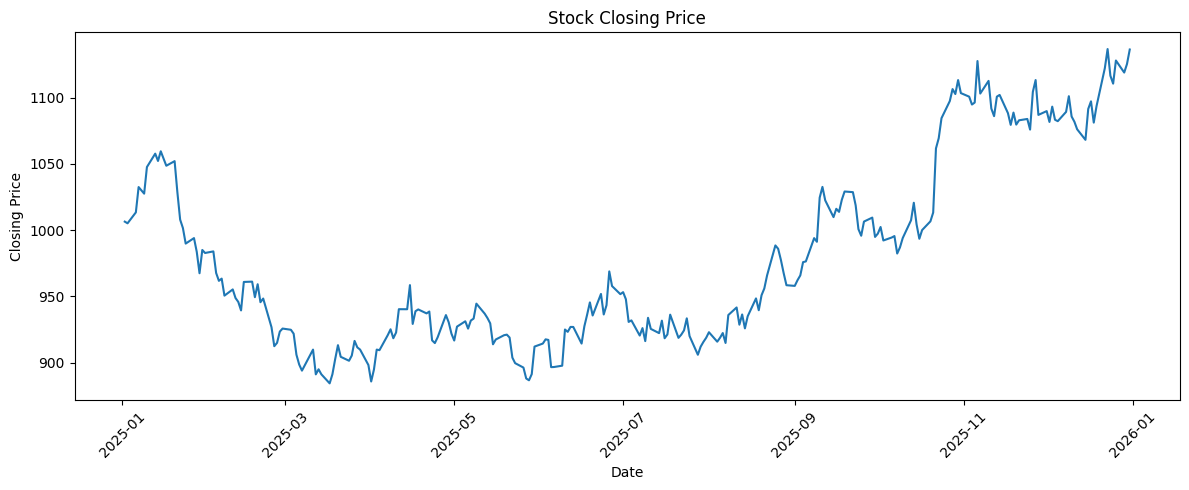

In [12]:
# --------------------------------------------------
# 5. Plot Closing Price
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Close"])

plt.title("Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

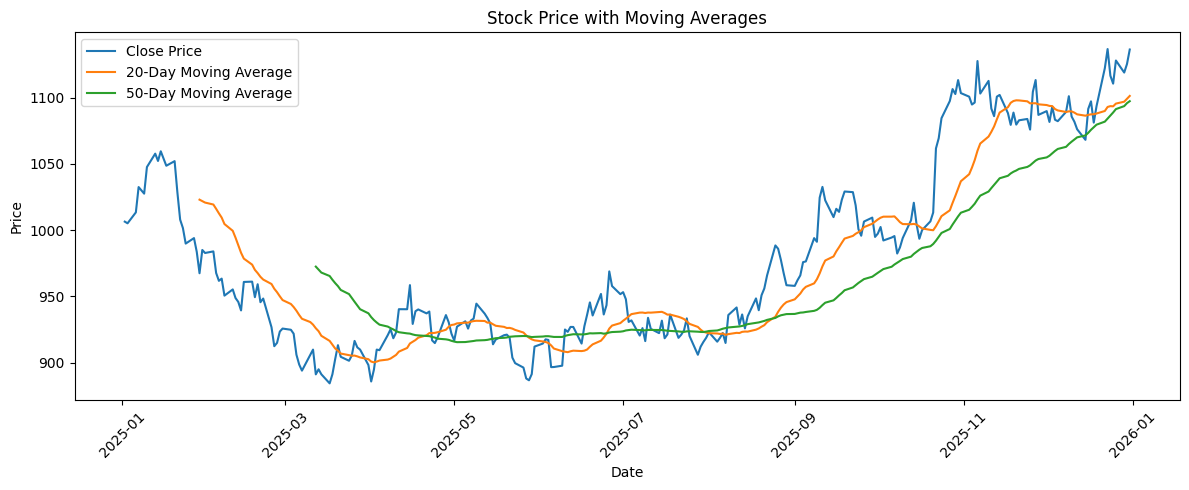

In [13]:
# --------------------------------------------------
# 6. Closing Price with Moving Averages
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Close"], label="Close Price")
plt.plot(df["Date"], df["MA_20"], label="20-Day Moving Average")
plt.plot(df["Date"], df["MA_50"], label="50-Day Moving Average")

plt.title("Stock Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


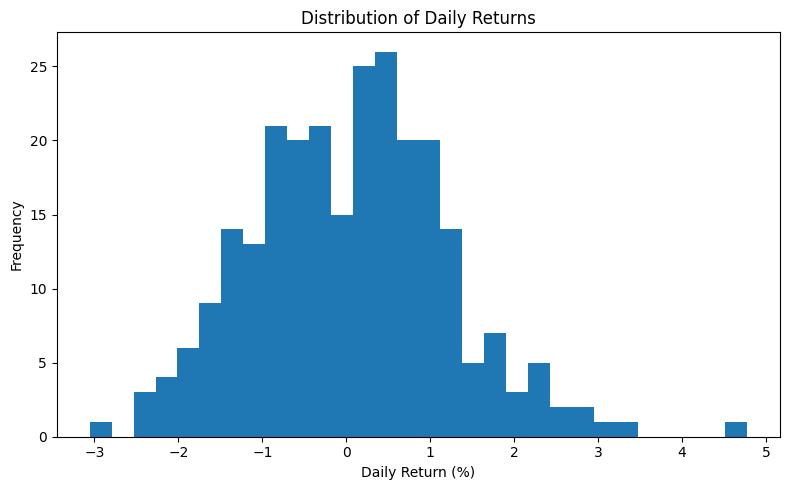

In [14]:
# --------------------------------------------------
# 7. Daily Return Distribution
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(df["Daily_Return_%"].dropna(), bins=30)

plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


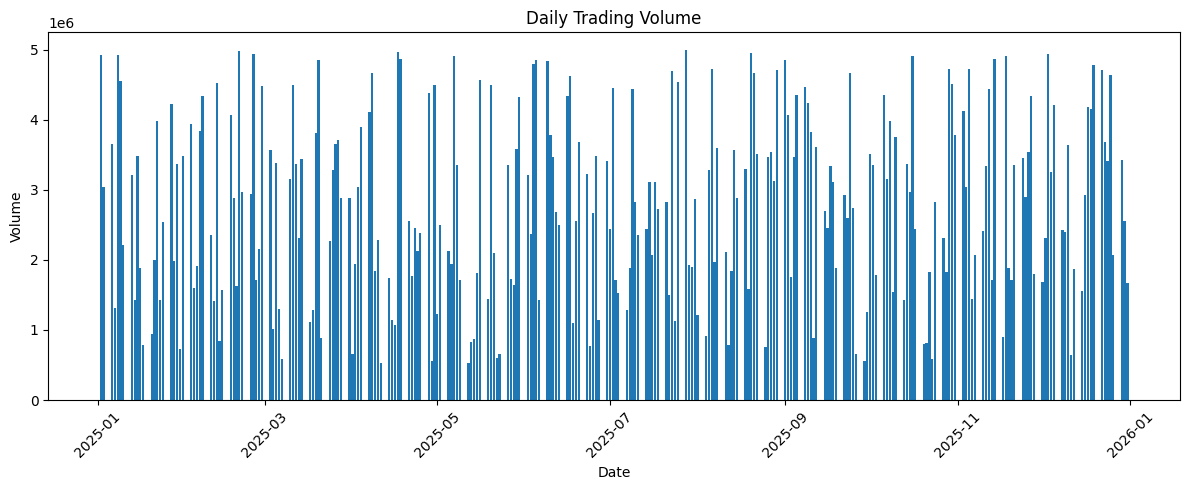

In [15]:
# --------------------------------------------------
# 8. Trading Volume Analysis
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.bar(df["Date"], df["Volume"])

plt.title("Daily Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [16]:
# --------------------------------------------------
# 9. Correlation Analysis
# --------------------------------------------------

print("\nCorrelation Matrix:")
print(df[["Open", "High", "Low", "Close", "Volume"]].corr())

# --------------------------------------------------
# 10. Simple Buy/Sell Signal
# --------------------------------------------------

df["Signal"] = ""

df.loc[df["MA_20"] > df["MA_50"], "Signal"] = "BUY"
df.loc[df["MA_20"] < df["MA_50"], "Signal"] = "SELL"

print("\nLatest Stock Signal:")
print(df[["Date", "Close", "MA_20", "MA_50", "Signal"]].tail(10))


Correlation Matrix:
            Open      High       Low     Close    Volume
Open    1.000000  0.997301  0.996968  0.998481  0.073621
High    0.997301  1.000000  0.994561  0.997039  0.069386
Low     0.996968  0.994561  1.000000  0.996885  0.068917
Close   0.998481  0.997039  0.996885  1.000000  0.075276
Volume  0.073621  0.069386  0.068917  0.075276  1.000000

Latest Stock Signal:
          Date    Close      MA_20      MA_50 Signal
250 2025-12-18  1081.12  1087.4380  1077.5616    BUY
251 2025-12-19  1093.53  1087.9720  1079.5524    BUY
252 2025-12-22  1122.19  1089.8880  1081.8482    BUY
253 2025-12-23  1136.63  1092.9265  1084.1684    BUY
254 2025-12-24  1116.54  1093.5365  1086.4134    BUY
255 2025-12-25  1110.52  1093.4015  1088.7548    BUY
256 2025-12-26  1127.98  1095.4540  1091.3142    BUY
257 2025-12-29  1118.89  1096.9085  1093.5600    BUY
258 2025-12-30  1125.32  1099.0940  1095.8016    BUY
259 2025-12-31  1136.28  1101.2495  1097.2950    BUY
